In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task2-salmon.ipynb")

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

**UPDATE THIS LINK**
https://github.com/Karlavramos/eds220-hwk2


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

<Axes: title={'center': 'Estimated average salmon catches by region from 1878 to 1997'}, xlabel='Average Catches (in thousands of fish)', ylabel='Region'>

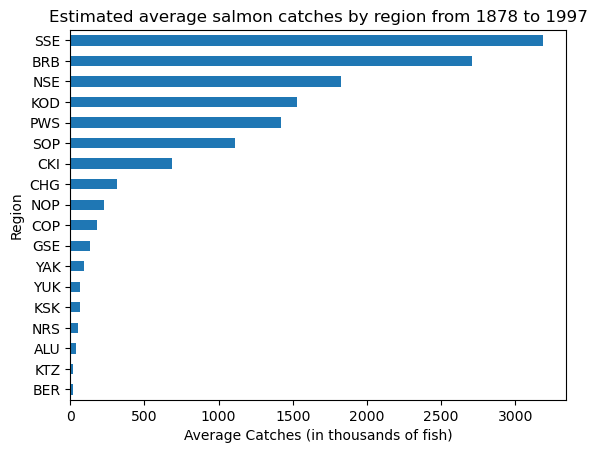

In [3]:
# Import pandas
import pandas as pd

# Upload Salmon data csv
catch_data = pd.read_csv('data/salmon_data.csv')

# Select notesRegCode column and find the unique values
notes_unique = catch_data['notesRegCode'].unique()

# Drop notesRegCode from data frame 
catch_data = catch_data.drop(columns=["notesRegCode"])

# Filter for the value "I" in column 'Catch' by creating a conditional statment 
catch_I = catch_data[catch_data['Catch'] == 'I']

# Update value "I" in column 'Catch' and set to 1
catch_data.at[400,'Catch'] = 1

# Update the data tye of catch column to be an integer 
catch_data['Catch']= catch_data['Catch'].astype('int64')

# Create a new data frame named avg_region with average per region
avg_region = catch_data.groupby('Region')['Catch'].mean()

# Visualize estimated salmon catches by region from 1878 to 1997
avg_region.sort_values().plot.barh(title="Estimated average salmon catches by region from 1878 to 1997", xlabel = 'Average Catches (in thousands of fish)')







## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



In [3]:
# a.

# Import pandas
import pandas as pd

# Upload Salmon data csv
catch_data = pd.read_csv('data/salmon_data.csv')


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [4]:
# b.

# Use .head() to look at the first 5 rows 
print(catch_data.head())

# Use .tail() to look at the last 5 rows 
print(catch_data.tail())

# View key information of data frame
print(catch_data.info())

# Check the amount of NaN in each column
print(catch_data.isna().sum())

  Region  Year notesRegCode  Species Catch
0    SSE  1886          NaN  Chinook     0
1    SSE  1887          NaN  Chinook     0
2    SSE  1888          NaN  Chinook     0
3    SSE  1889          NaN  Chinook     0
4    SSE  1890          NaN  Chinook     0
     Region  Year notesRegCode Species Catch
8535    NOP  1993          NaN    Chum   135
8536    NOP  1994          NaN    Chum    84
8537    NOP  1995          NaN    Chum    99
8538    NOP  1996          NaN    Chum    68
8539    NOP  1997          NaN    Chum    97
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Region        8540 non-null   object
 1   Year          8540 non-null   int64 
 2   notesRegCode  1415 non-null   object
 3   Species       8540 non-null   object
 4   Catch         8540 non-null   object
dtypes: int64(1), object(4)
memory usage: 333.7+ KB
None
Region         

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

In my exploratory analysis of the data frame I used .head() to look at the first 5 rows and .tail() to look at the last 5 rows. To view key information of the data frame I used .info() to see the top 5 rows alonf with thier desiganted dtype. Finally, I found all of the NaNs in each column and it provided intersting insight that colum notesRegCode has most entires missing. 

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [5]:
# Select notesRegCode column and find the unique values
notes_unique = catch_data['notesRegCode'].unique()
print(notes_unique)

[nan 'Includes Yakutat catches' 'Yakutat catch included in No SE AK catch'
 'Estimated from canned production, probably sockeye' 'No fishery'
 'Bering River catches included in Copper River catches'
 'Includes Bering River catches; estimated from canned'
 'Includes Bering River catches'
 'Coho and pink catch estimated from canned production'
 'Includes Bering River; coho and pink estimated fro canned'
 'Pink catch estimated from canned'
 'Includes Bering River; coho pink and chum estimated from canned'
 'Includes Bering River; pink estimated from canned'
 'Includes Bering River; pink and chum estimated from canned'
 'Includes Copper River catches'
 'Includes Copper River catches; coho catch porbably mostly pinks'
 'Eshamy District only' 'Estimated from canned; excludes Resurrection Bay'
 'Estimated from canned production' 'No Resurrection Bay fishery'
 'Resurrection bay contribution estimated from canned production'
 'No reported catch'
 'Sockeye and pink and 9922 chum from Port Claren

In [6]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [7]:
# Drop notesRegCode from data frame 
catch_data = catch_data.drop(columns=["notesRegCode"])

In [8]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


In [9]:
# Check the dtype of the values in eahc column
catch_data.dtypes

Region     object
Year        int64
Species    object
Catch      object
dtype: object

When checking the dtypes of each column, I was surprised that the column `Year` was an integer and not a datetime. Depending on the analysis it would be something that should be changed. 

<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [10]:
catch_data['Catch'].astype('int64')

ValueError: invalid literal for int() with base 10: 'I'

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [11]:
# Filter for the value "I" in column 'Catch' by creating a conditional statment 
catch_I = catch_data[catch_data['Catch'] == 'I']
catch_I 

,Region,Year,Species,Catch
400,GSE,1955,Chinook,I


In [12]:
grader.check("q5")

q5 results: All test cases passed!

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

<!-- BEGIN QUESTION -->



In [13]:
# Update value "I" in column 'Catch' and set to 1
catch_data.at[400,'Catch'] = 1

# Ensure the change was done correctly by locating 400 row
catch_data.loc[400, 'Catch']

1

In [ ]:
catch_1 = catch_data.at[400,'Catch'] = 1

# Print catch_1
print(catch_1 )

1


<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [ ]:
# Update the data tye of catch column to be an integer 
catch_data['Catch']= catch_data['Catch'].astype('int64')
catch_column_type = catch_data['Catch'].dtype
catch_column_type

dtype('int64')

In [16]:
grader.check("q7")

q7 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [ ]:
# Create a data frame with the average salmon catch per region
catch_data.groupby('Region')['Catch'].mean()

Region
ALU      40.383908
BER      16.372549
BRB    2709.796491
CHG     315.487273
CKI     683.571429
COP     179.223404
GSE     133.841463
KOD    1528.350000
KSK      67.642353
KTZ      18.836145
NOP     229.493478
NRS      51.502703
NSE    1825.020870
PWS    1419.236697
SOP    1110.942222
SSE    3184.660714
YAK      91.922917
YUK      68.645570
Name: Catch, dtype: float64

In [ ]:
# Create a new data frame named avg_region with average per region
avg_region = catch_data.groupby('Region')['Catch'].mean()

print(avg_region)

Region
ALU      40.383908
BER      16.372549
BRB    2709.796491
CHG     315.487273
CKI     683.571429
COP     179.223404
GSE     133.841463
KOD    1528.350000
KSK      67.642353
KTZ      18.836145
NOP     229.493478
NRS      51.502703
NSE    1825.020870
PWS    1419.236697
SOP    1110.942222
SSE    3184.660714
YAK      91.922917
YUK      68.645570
Name: Catch, dtype: float64


In [28]:
grader.check("q8")

q8 results: All test cases passed!

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

<Axes: title={'center': 'Estimated average salmon catches by region from 1878 to 1997'}, xlabel='Average Catches (in thousands of fish)', ylabel='Region'>

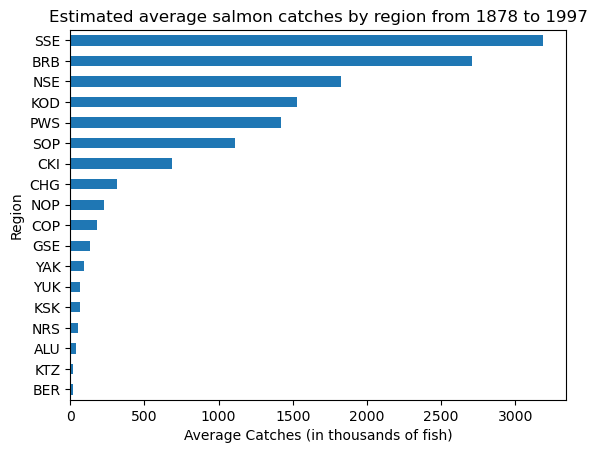

In [ ]:
# Visualize estimated salmon catches by region from 1878 to 1997
avg_region.sort_values().plot.barh(title="Estimated average salmon catches by region from 1878 to 1997", xlabel = 'Average Catches (in thousands of fish)')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

The bar graph highlights that Southern Southeast Alaska (SSE) had the most average Salmon catches from 1878 to 1997. The region with the least catches in this time frame is Bering River Subarea (BER). There is over a 3000 diffrence between the amount of catches that can be seen from printing the data frame, but plotting it puts into perspective the diffrence in values between all of the regions. 

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [42]:
grader.check_all()

q2a results: All test cases passed!

q2b results: All test cases passed!

q5 results: All test cases passed!

q7 results: All test cases passed!

q8 results: All test cases passed!